# Nepal Earthquake Building Damage Prediction
### Machine Learning Mini-Project

**Objective:** Predict building damage grade (1, 2, or 3) using structural, geographic, and building-use features from the 2015 Nepal earthquake dataset.

This notebook contains:
1. Dataset loading and validation
2. Exploratory data analysis (EDA)
3. Explicit alignment of training labels by `building_id`
4. Train/validation split and preprocessing
5. Baseline Random Forest evaluation
6. Fair comparison of Random Forest and Extra Trees on the same sample and validation set
7. Feature importance analysis
8. Final model training on all labelled data and test prediction export

**Important:** Validation metrics are calculated only on the held-out validation split. The provided test dataset has no labels, so its accuracy cannot be calculated locally.

## 1. Imports and dataset paths

This notebook is configured for the Kaggle dataset path used in the original notebook. If Kaggle mounts the dataset at a different path, update `DATA_DIR` below.

### Load Libraries and Configure Dataset Path


In [2]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42
DATA_DIR = "/kaggle/input/datasets/ggo4411/nepal-earthquake-datasets"

required_files = [
    "train_values.csv", "train_labels.csv",
    "test_values.csv", "submission_format.csv"
]
missing_files = [name for name in required_files
                 if not os.path.exists(os.path.join(DATA_DIR, name))]
if missing_files:
    raise FileNotFoundError(
        f"Could not find {missing_files} under {DATA_DIR}. "
        "Check the dataset path in Kaggle's Input panel."
    )

train_values = pd.read_csv(os.path.join(DATA_DIR, "train_values.csv"))
train_labels = pd.read_csv(os.path.join(DATA_DIR, "train_labels.csv"))
test_values = pd.read_csv(os.path.join(DATA_DIR, "test_values.csv"))
submission_format = pd.read_csv(os.path.join(DATA_DIR, "submission_format.csv"))

print("Train features:", train_values.shape)
print("Train labels:", train_labels.shape)
print("Test features:", test_values.shape)
print("Submission format:", submission_format.shape)

Train features: (260601, 39)
Train labels: (260601, 2)
Test features: (86868, 39)
Submission format: (86868, 2)


## 2. Validate files and align labels

The labels are explicitly joined to the feature rows using `building_id`; the notebook does not assume that CSV row order is correct.

### Validate Dataset and Align Labels by Building ID


In [3]:
required_train_cols = {"building_id"}
required_label_cols = {"building_id", "damage_grade"}

assert required_train_cols.issubset(train_values.columns), "train_values is missing building_id."
assert required_label_cols.issubset(train_labels.columns), "train_labels must contain building_id and damage_grade."
assert "building_id" in test_values.columns, "test_values is missing building_id."
assert train_values["building_id"].is_unique, "Duplicate building_id values found in train_values."
assert train_labels["building_id"].is_unique, "Duplicate building_id values found in train_labels."
assert test_values["building_id"].is_unique, "Duplicate building_id values found in test_values."

# Check that the feature and label files contain exactly the same training IDs.
feature_ids = set(train_values["building_id"])
label_ids = set(train_labels["building_id"])
assert feature_ids == label_ids, (
    f"Training IDs do not match: {len(feature_ids-label_ids)} feature-only IDs, "
    f"{len(label_ids-feature_ids)} label-only IDs."
)

# Merge labels by ID, preserving the feature table's order.
train_data = train_values.merge(
    train_labels[["building_id", "damage_grade"]],
    on="building_id",
    how="left",
    validate="one_to_one",
    sort=False
)
assert train_data["damage_grade"].notna().all(), "Some training rows have no label after merge."
assert len(train_data) == len(train_values) == len(train_labels)

print("Label alignment check passed.")
print("Merged training data:", train_data.shape)
print("\nMissing feature values:", train_values.isna().sum().sum())
print("Missing label values:", train_data["damage_grade"].isna().sum())
print("Duplicate feature rows excluding building_id:",
      train_values.drop(columns=["building_id"]).duplicated().sum())
print("\nDamage grade counts:")
display(train_data["damage_grade"].value_counts().sort_index().rename("count").to_frame())

Label alignment check passed.
Merged training data: (260601, 40)

Missing feature values: 0
Missing label values: 0
Duplicate feature rows excluding building_id: 16191

Damage grade counts:


,count
damage_grade,
1,25124
2,148259
3,87218


## 3. Exploratory data analysis

### Analyse Damage Grade Distribution


,Building Count,Percentage (%)
damage_grade,,
1,25124,9.64
2,148259,56.89
3,87218,33.47


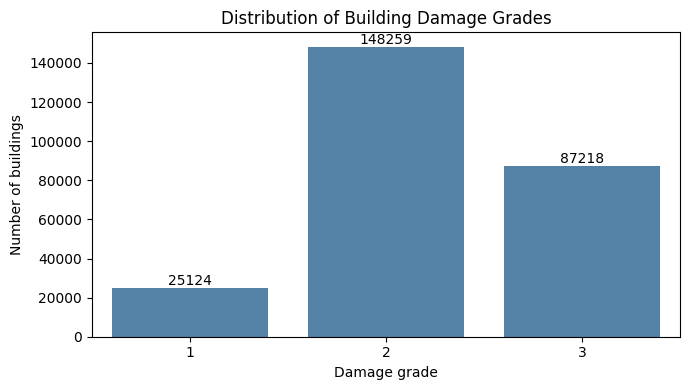

In [4]:
damage_counts = train_data["damage_grade"].value_counts().sort_index()
damage_summary = pd.DataFrame({
    "Building Count": damage_counts,
    "Percentage (%)": (damage_counts / len(train_data) * 100).round(2)
})
display(damage_summary)

plt.figure(figsize=(7, 4))
ax = sns.countplot(data=train_data, x="damage_grade", color="steelblue")
ax.set(title="Distribution of Building Damage Grades",
       xlabel="Damage grade", ylabel="Number of buildings")
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")
plt.tight_layout()
plt.show()

### Inspect Feature Types and Foundation Damage Patterns


Feature data types:


,column_count
int64,31
object,8


Text/category columns (8): ['land_surface_condition', 'foundation_type', 'roof_type', 'ground_floor_type', 'other_floor_type', 'position', 'plan_configuration', 'legal_ownership_status']
Missing values per feature (only non-zero shown):


,missing_count


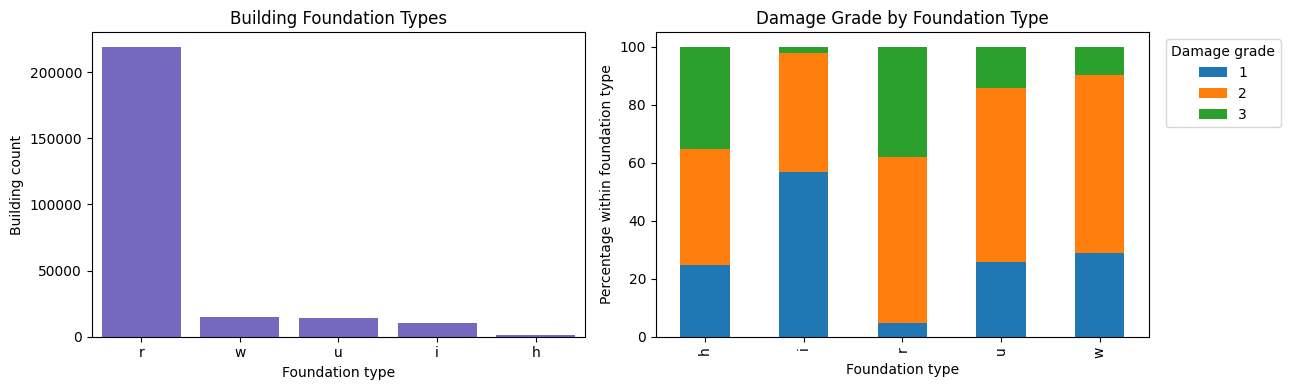

In [5]:
print("Feature data types:")
display(train_values.dtypes.value_counts().rename("column_count").to_frame())

categorical_columns = train_values.select_dtypes(
    include=["object", "category"]
).columns.tolist()
print(f"Text/category columns ({len(categorical_columns)}):", categorical_columns)
print("Missing values per feature (only non-zero shown):")
display(train_values.isna().sum().loc[lambda s: s > 0].to_frame("missing_count"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=train_values, x="foundation_type",
              order=train_values["foundation_type"].value_counts().index,
              color="slateblue", ax=axes[0])
axes[0].set(title="Building Foundation Types",
            xlabel="Foundation type", ylabel="Building count")
foundation_damage = pd.crosstab(
    train_data["foundation_type"], train_data["damage_grade"], normalize="index"
).mul(100)
foundation_damage.plot(kind="bar", stacked=True, ax=axes[1])
axes[1].set(title="Damage Grade by Foundation Type",
            xlabel="Foundation type", ylabel="Percentage within foundation type")
axes[1].legend(title="Damage grade", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Investigate Building Age and Unusual Values


Building age summary:


,age
count,260601.000000
mean,26.535029
std,73.565937
min,0.000000
50%,15.000000
90%,45.000000
95%,60.000000
99%,100.000000
99.9%,995.000000
max,995.000000


Buildings with recorded age > 100 years: 2124
Buildings with recorded age = 995 years: 1390


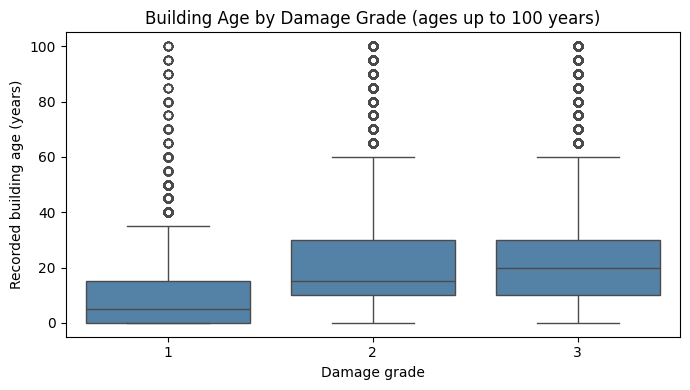

In [6]:
print("Building age summary:")
display(train_values["age"].describe(percentiles=[.5, .9, .95, .99, .999]).to_frame())
print("Buildings with recorded age > 100 years:", int((train_values["age"] > 100).sum()))
print("Buildings with recorded age = 995 years:", int((train_values["age"] == 995).sum()))

# Show the central age distribution so extreme recorded values do not flatten the plot.
age_plot = train_data.loc[train_data["age"] <= 100, ["age", "damage_grade"]]
plt.figure(figsize=(7, 4))
sns.boxplot(data=age_plot, x="damage_grade", y="age", color="steelblue")
plt.title("Building Age by Damage Grade (ages up to 100 years)")
plt.xlabel("Damage grade")
plt.ylabel("Recorded building age (years)")
plt.tight_layout()
plt.show()

### Initial EDA observations

- Damage grade 2 is the most common class, so accuracy alone may hide weaker performance on the less common grade 1.
- Foundation type and building age show descriptive associations with damage grade; these charts do not establish causation.
- Some age values are unusually large (including 995). They are retained in the baseline rather than silently removed; their meaning should be treated as a data-quality limitation.
- Duplicate feature rows can occur for different buildings. They are not automatically deleted because each building has its own label and ID.

## 4. Define features, target, and stratified validation split

`building_id` is used for alignment and output only, not as a predictive feature. Geographic IDs are handled as categorical codes.

### Create Stratified Training and Validation Sets


In [7]:
X = train_data.drop(columns=["building_id", "damage_grade"]).copy()
y = train_data["damage_grade"].astype(int).copy()
X_test = test_values.drop(columns=["building_id"]).copy()

# Ensure test feature columns match the training feature columns and order.
assert list(X.columns) == list(X_test.columns), (
    "Train/test feature columns differ. Inspect column names and ordering before training."
)

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Training split:", X_train.shape, y_train.shape)
print("Validation split:", X_val.shape, y_val.shape)
print("\nTraining class proportions:")
display(y_train.value_counts(normalize=True).sort_index().rename("proportion").to_frame())
print("Validation class proportions:")
display(y_val.value_counts(normalize=True).sort_index().rename("proportion").to_frame())

Training split: (208480, 38) (208480,)
Validation split: (52121, 38) (52121,)

Training class proportions:


,proportion
damage_grade,
1,0.096407
2,0.568913
3,0.334680


Validation class proportions:


,proportion
damage_grade,
1,0.096410
2,0.568907
3,0.334683


## 5. Preprocessing and baseline Random Forest

One-hot encoding is fitted inside each pipeline, preventing validation data from being used to fit the encoder. Unknown categories in validation/test data are ignored safely.

### Define Categorical and Numerical Preprocessing


In [8]:
text_categorical = X.select_dtypes(include=["object", "category"]).columns.tolist()
geo_categorical = [
    col for col in ["geo_level_1_id", "geo_level_2_id", "geo_level_3_id"]
    if col in X.columns
]
categorical_features = list(dict.fromkeys(text_categorical + geo_categorical))
numeric_features = [col for col in X.columns if col not in categorical_features]

def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            ("categorical",
             OneHotEncoder(handle_unknown="ignore"),
             categorical_features),
            ("numeric", "passthrough", numeric_features)
        ],
        remainder="drop"
    )

print("Categorical features:", len(categorical_features))
print("Numeric features:", len(numeric_features))

Categorical features: 11
Numeric features: 27


### Train and Evaluate the Baseline Random Forest


,training_rows,accuracy,macro_f1,weighted_f1,fit_seconds
model,,,,,
Random Forest baseline (full split),208480,0.731931,0.680136,0.727669,757.6


              precision    recall  f1-score   support

           1     0.6568    0.5186    0.5796      5025
           2     0.7410    0.8250    0.7808     29652
           3     0.7318    0.6352    0.6801     17444

    accuracy                         0.7319     52121
   macro avg     0.7099    0.6596    0.6801     52121
weighted avg     0.7298    0.7319    0.7277     52121



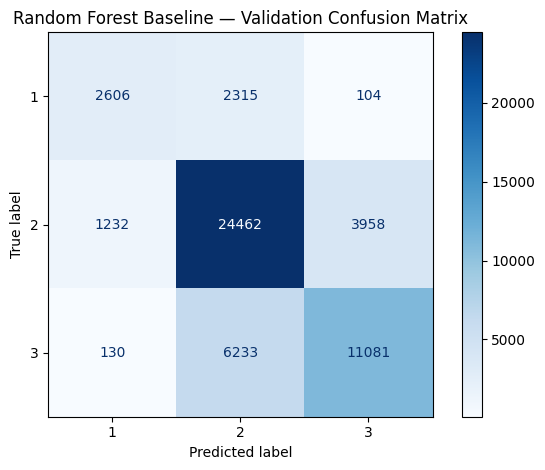

In [9]:
baseline_rf = Pipeline(steps=[
    ("preprocessor", make_preprocessor()),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

start_time = time.time()
baseline_rf.fit(X_train, y_train)
baseline_seconds = time.time() - start_time

baseline_val_pred = baseline_rf.predict(X_val)
baseline_metrics = {
    "model": "Random Forest baseline (full split)",
    "training_rows": len(X_train),
    "accuracy": accuracy_score(y_val, baseline_val_pred),
    "macro_f1": f1_score(y_val, baseline_val_pred, average="macro"),
    "weighted_f1": f1_score(y_val, baseline_val_pred, average="weighted"),
    "fit_seconds": round(baseline_seconds, 1)
}
display(pd.DataFrame([baseline_metrics]).set_index("model"))

print(classification_report(y_val, baseline_val_pred, digits=4, zero_division=0))
ConfusionMatrixDisplay.from_predictions(
    y_val, baseline_val_pred, cmap="Blues", values_format="d"
)
plt.title("Random Forest Baseline — Validation Confusion Matrix")
plt.tight_layout()
plt.show()

## 6. Fair model comparison: Random Forest vs Extra Trees

To keep this comparison computationally manageable, both models below use **the same stratified sample from `X_train`**, the same untouched `X_val`/`y_val`, and the same metrics. This is a fair comparison between these two sampled experiments, but it is not a direct apples-to-apples comparison with the full-data baseline above.

The baseline is retained as the main full-training-split result. The sample size is controlled by `COMPARISON_FRACTION`; increase it only if runtime allows.

### Create Stratified Training and Validation Sets


In [10]:
COMPARISON_FRACTION = 0.25

X_compare, _, y_compare, _ = train_test_split(
    X_train, y_train,
    train_size=COMPARISON_FRACTION,
    random_state=RANDOM_STATE,
    stratify=y_train
)
print(f"Comparison training rows per model: {len(X_compare):,} "
      f"({COMPARISON_FRACTION:.0%} of the training split)")

Comparison training rows per model: 52,120 (25% of the training split)


### Compare Random Forest and Extra Trees Fairly


In [11]:
comparison_models = {
    "Random Forest (sample)": RandomForestClassifier(
        n_estimators=50, max_depth=30, min_samples_leaf=2,
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Extra Trees (sample)": ExtraTreesClassifier(
        n_estimators=100, max_depth=30, min_samples_leaf=2,
        random_state=RANDOM_STATE, n_jobs=-1
    )
}

comparison_pipelines = {}
comparison_results = []

for name, estimator in comparison_models.items():
    pipeline = Pipeline([
        ("preprocessor", make_preprocessor()),
        ("classifier", estimator)
    ])
    start_time = time.time()
    pipeline.fit(X_compare, y_compare)
    fit_seconds = time.time() - start_time
    pred = pipeline.predict(X_val)

    comparison_pipelines[name] = pipeline
    comparison_results.append({
        "model": name,
        "training_rows": len(X_compare),
        "accuracy": accuracy_score(y_val, pred),
        "macro_f1": f1_score(y_val, pred, average="macro"),
        "weighted_f1": f1_score(y_val, pred, average="weighted"),
        "fit_seconds": round(fit_seconds, 1)
    })

comparison_df = pd.DataFrame(comparison_results).sort_values(
    "macro_f1", ascending=False
)
display(comparison_df)

,model,training_rows,accuracy,macro_f1,weighted_f1,fit_seconds
0,Random Forest (sample),52120,0.653230,0.468739,0.591402,1.0
1,Extra Trees (sample),52120,0.647915,0.454838,0.578720,1.9


### Interpreting the comparison

Use **macro F1** as the primary selection metric because the three damage grades have different class frequencies. Accuracy and weighted F1 are also reported for context. Runtime depends on Kaggle resources and should not be treated as a stable benchmark.

The full-data baseline and sampled comparison have different training sizes, so don't rank them as if the training conditions were identical. The fair comparison above is the Random Forest sample versus Extra Trees sample.

## 7. Feature importance from the baseline Random Forest

Random Forest impurity-based importance is calculated for the fitted baseline. One-hot encoded category importances are aggregated back to their original input feature so the chart is easier to interpret. These importances describe model reliance, not causality.

### Calculate and Plot Random Forest Feature Importance


,original_feature,importance
7,geo_level_3_id,0.242982
6,geo_level_2_id,0.175403
0,age,0.114356
5,geo_level_1_id,0.098253
1,area_percentage,0.095661
31,height_percentage,0.041968
4,foundation_type,0.022358
2,count_families,0.020945
36,position,0.020579
8,ground_floor_type,0.019120


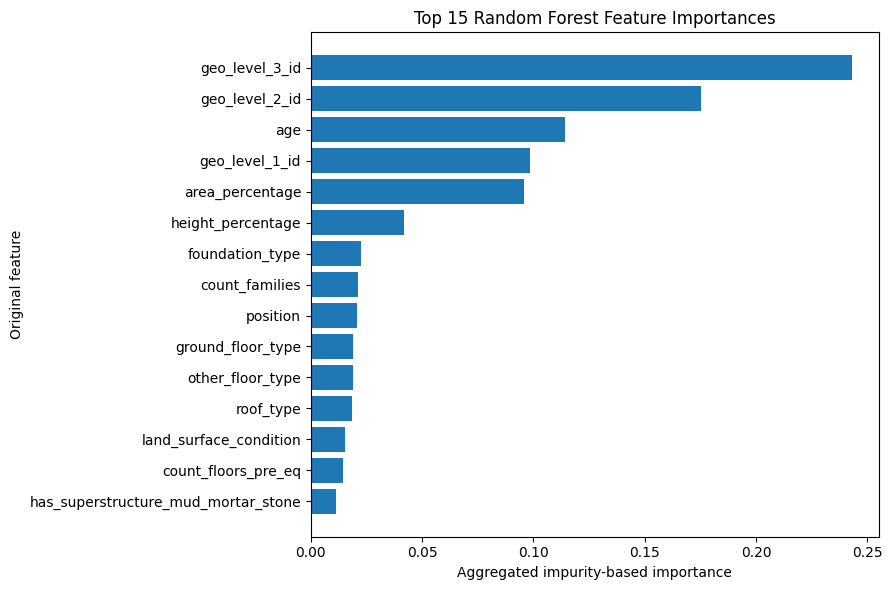

In [12]:
fitted_preprocessor = baseline_rf.named_steps["preprocessor"]
fitted_forest = baseline_rf.named_steps["classifier"]
transformed_names = fitted_preprocessor.get_feature_names_out()
raw_importances = fitted_forest.feature_importances_

importance_frame = pd.DataFrame({
    "transformed_feature": transformed_names,
    "importance": raw_importances
})

def original_feature_name(transformed_name):
    # ColumnTransformer names features as "categorical__..." or "numeric__...".
    if transformed_name.startswith("categorical__"):
        rest = transformed_name[len("categorical__"):]
        # Match the original categorical feature name before the one-hot category suffix.
        candidates = sorted(categorical_features, key=len, reverse=True)
        for col in candidates:
            if rest == col or rest.startswith(col + "_"):
                return col
        return rest
    if transformed_name.startswith("numeric__"):
        return transformed_name[len("numeric__"):]
    return transformed_name

importance_frame["original_feature"] = importance_frame["transformed_feature"].map(
    original_feature_name
)
grouped_importance = (
    importance_frame.groupby("original_feature", as_index=False)["importance"]
    .sum()
    .sort_values("importance", ascending=False)
)

display(grouped_importance.head(15))
top_importance = grouped_importance.head(15).sort_values("importance")
plt.figure(figsize=(9, 6))
plt.barh(top_importance["original_feature"], top_importance["importance"])
plt.xlabel("Aggregated impurity-based importance")
plt.ylabel("Original feature")
plt.title("Top 15 Random Forest Feature Importances")
plt.tight_layout()
plt.show()

### Feature-importance limitation

Impurity-based importance can favour high-cardinality variables and should not be interpreted as causal evidence. For a stronger future analysis, permutation importance on a representative validation sample could be added, but it is not required for this notebook to produce the requested baseline analysis.

## 8. Select a final model and train on all labelled data

For the final test predictions, this notebook uses the full-data Random Forest baseline configuration. This choice is reproducible and avoids choosing a model based on comparisons made with unequal training sizes. The validation results remain the honest estimate of performance; the test labels are not available locally.

### Train the Final Model on All Labelled Data


Final model configuration: same estimator settings as the baseline.
Fit preprocessing and model on all labelled examples after validation is complete.
final_model = Pipeline(steps=[
    ("preprocessor", make_preprocessor()),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

start_time = time.time()
final_model.fit(X, y)
print(f"Final model trained on {len(X):,} labelled examples "
      f"in {time.time() - start_time:.1f} seconds.")

In [14]:

# Generate predictions using the existing trained baseline
test_predictions = baseline_rf.predict(X_test)

# Align predictions with building IDs
prediction_frame = pd.DataFrame({
    "building_id": test_values["building_id"],
    "damage_grade": test_predictions
})

submission = submission_format.drop(
    columns=["damage_grade"], errors="ignore"
).merge(
    prediction_frame,
    on="building_id",
    how="left",
    validate="one_to_one",
    sort=False
)

assert len(submission) == len(test_values)
assert submission["damage_grade"].notna().all()

output_path = "/kaggle/working/nepal_earthquake_submission.csv"
submission.to_csv(output_path, index=False)

print("Submission saved:", output_path)
print("Shape:", submission.shape)
display(submission.head())


Submission saved: /kaggle/working/nepal_earthquake_submission.csv
Shape: (86868, 2)


,building_id,damage_grade
0,300051,2
1,99355,2
2,890251,2
3,745817,1
4,421793,3


## Final Model

The final test predictions reuse the trained baseline Random Forest model. Retraining on all labelled data was skipped to reduce computation time. Therefore, predictions are generated using the model trained on the 80% training split.


In [15]:

# Generate predictions using the already-trained baseline model
# No additional model training is required.

test_predictions = baseline_rf.predict(X_test)

# Align predictions with the test building IDs
prediction_frame = pd.DataFrame({
    "building_id": test_values["building_id"].to_numpy(),
    "damage_grade": test_predictions
})

# Preserve the submission template's expected format
submission = submission_format.drop(
    columns=["damage_grade"], errors="ignore"
).merge(
    prediction_frame,
    on="building_id",
    how="left",
    validate="one_to_one",
    sort=False
)

# Validate the output
assert len(submission) == len(test_values)
assert submission["damage_grade"].notna().all()
assert set(submission["damage_grade"].unique()).issubset({1, 2, 3})

# Save the final CSV
OUTPUT_PATH = "/kaggle/working/nepal_earthquake_submission.csv"
submission.to_csv(OUTPUT_PATH, index=False)

print("Submission saved successfully!")
print("File:", OUTPUT_PATH)
print("Shape:", submission.shape)
print("\nPredicted damage-grade distribution:")
display(submission["damage_grade"].value_counts().sort_index().to_frame("count"))
display(submission.head())


Submission saved successfully!
File: /kaggle/working/nepal_earthquake_submission.csv
Shape: (86868, 2)

Predicted damage-grade distribution:


,count
damage_grade,
1,6545
2,55332
3,24991


,building_id,damage_grade
0,300051,2
1,99355,2
2,890251,2
3,745817,1
4,421793,3


## 9. Results summary and conclusion

The baseline Random Forest provides the principal full-data validation result. The additional Random Forest and Extra Trees runs form a fair comparison because they use the same sampled training rows and validation set. Feature importance gives an interpretable view of which recorded building characteristics the baseline model uses most.

The final submission file contains predictions for the provided test buildings, but its real test performance is unknown unless the predictions are evaluated by a labelled benchmark/competition.

### Limitations
- The target classes are imbalanced, especially damage grade 1.
- Very large recorded building ages may represent unusual or noisy records.
- Feature importance is not causal.
- The model is trained on historical Nepal earthquake survey data and should not be treated as a substitute for structural engineering inspection.